In [8]:
from analysisManager import stage

In [9]:
load = 1e3 # 1kN load
length = 2 # 2m long cantilever
youngsModulus = 200e8 # for steel
density = 7850 # for steel

def rectangularCantileverDeflection(depth,width,**kwargs):
	I = depth**3 * width / 12
	deflection = load * length**3 / (4 * youngsModulus * I)
	return {'deflection':deflection}

def getMass(depth,width,**kwargs):
	volume = depth * width * length
	mass = volume * density
	return {'mass':mass}

deflectionStage = stage(rectangularCantileverDeflection, inputs = ['depth','width'],name = 'Cantilever deflection')
massStage = stage(getMass,inputs = ['depth','width'],name = 'Mass')

stages = [deflectionStage,massStage] 

In [10]:
from analysisManager import basicSampler

sampler = basicSampler(
	depth = (0.3,0.75),
	width = (0.1,0.3)
)

In [11]:
from analysisManager import searchRoutine, optimiseRoutine

searcher = searchRoutine(sampler,method = 'sobol',density = 6) # you can search in different patterns

from numpy import inf
valueFunction = lambda row: [row.get('mass',inf), row.get('deflection',inf)] # this is the function that will be optimised. It takes a row of the runManager.df DataFrame and returns a list of values to be minimised. In this case, we want to minimise both mass and deflection.
optimiser = optimiseRoutine(sampler = sampler,targetFunction = valueFunction)

In [12]:
from analysisManager import runManager

runner = runManager(stages = stages, routines = [searcher,optimiser], name='Example',verbose = True)
runner.runRoutines()

Search: running 1 of 64 | Stage 1 of 2 (dce9efc7c083)
Search: running 1 of 64 | Stage 2 of 2 (dce9efc7c083)
Search: running 2 of 64 | Stage 1 of 2 (2f7179e4b579)
Search: running 2 of 64 | Stage 2 of 2 (2f7179e4b579)
Search: running 3 of 64 | Stage 1 of 2 (fe0c7a505a27)
Search: running 3 of 64 | Stage 2 of 2 (fe0c7a505a27)
Search: running 4 of 64 | Stage 1 of 2 (6407a9b43dc4)
Search: running 4 of 64 | Stage 2 of 2 (6407a9b43dc4)
Search: running 5 of 64 | Stage 1 of 2 (93df3b437010)
Search: running 5 of 64 | Stage 2 of 2 (93df3b437010)
Search: running 6 of 64 | Stage 1 of 2 (71b9d7bd10cd)
Search: running 6 of 64 | Stage 2 of 2 (71b9d7bd10cd)
Search: running 7 of 64 | Stage 1 of 2 (cdb5435ce45e)
Search: running 7 of 64 | Stage 2 of 2 (cdb5435ce45e)
Search: running 8 of 64 | Stage 1 of 2 (acc4b672f0d5)
Search: running 8 of 64 | Stage 2 of 2 (acc4b672f0d5)
Search: running 9 of 64 | Stage 1 of 2 (4ad0fdc8c3ab)
Search: running 9 of 64 | Stage 2 of 2 (4ad0fdc8c3ab)
Search: running 10 of 64 | S

In [13]:
candidates = searcher.getResultPopulation(target = 'deflection',nLen = 10) # get the 10 best candidates from the search routine, based on the deflection value. This can be used as the initial population for the optimisation routine.
newOptimiser = optimiseRoutine(sampler = sampler,targetFunction = valueFunction,initialPopulation = candidates) # add these to a new optimisation routine, which will use these candidates as the initial population for the optimisation. This is useful if you want to do a more focused optimisation after a broad search.
runner.runRoutine(newOptimiser)

2 Objective Optimiser: running 1 | Stage 1 of 2 (89ad5efca4f4)
2 Objective Optimiser: running 1 | Stage 2 of 2 (89ad5efca4f4)
2 Objective Optimiser: running 2 | Stage 1 of 2 (12a271afc33b)
2 Objective Optimiser: running 2 | Stage 2 of 2 (12a271afc33b)
2 Objective Optimiser: running 3 | Stage 1 of 2 (5646c12bdf4b)
2 Objective Optimiser: running 3 | Stage 2 of 2 (5646c12bdf4b)
2 Objective Optimiser: running 4 | Stage 1 of 2 (4cba024d21e3)
2 Objective Optimiser: running 4 | Stage 2 of 2 (4cba024d21e3)
2 Objective Optimiser: running 5 | Stage 1 of 2 (48db88166afd)
2 Objective Optimiser: running 5 | Stage 2 of 2 (48db88166afd)
2 Objective Optimiser: running 6 | Stage 1 of 2 (69f3499459dc)
2 Objective Optimiser: running 6 | Stage 2 of 2 (69f3499459dc)
2 Objective Optimiser: running 7 | Stage 1 of 2 (1b5a77e88c62)
2 Objective Optimiser: running 7 | Stage 2 of 2 (1b5a77e88c62)
2 Objective Optimiser: running 8 | Stage 1 of 2 (8ea08731ad6e)
2 Objective Optimiser: running 8 | Stage 2 of 2 (8ea087

In [14]:
optimisation_configuration = {
	'n_gen': 40,
	'pop_size': 30,
	'sampling':candidates,
	'n_offsprings':20
}
runner.runRoutines(**optimisation_configuration) # Running routines can also take additional keyword arguments, which will be passed to the routines. In this case, we are passing the optimisation configuration to the optimiser routine.
#Note:
# All routines receive the same keyword arguments, so run the routines separately if you want more granular control.
# like...
# runner.runRoutine(searcher)
# runner.runRoutine(optimiser,**optimisation_configuration)

Search: running 1 of 64 | Stage 1 of 2 (dce9efc7c083)
Search: running 1 of 64 | Stage 2 of 2 (dce9efc7c083)
Search: running 2 of 64 | Stage 1 of 2 (2f7179e4b579)
Search: running 2 of 64 | Stage 2 of 2 (2f7179e4b579)
Search: running 3 of 64 | Stage 1 of 2 (fe0c7a505a27)
Search: running 3 of 64 | Stage 2 of 2 (fe0c7a505a27)
Search: running 4 of 64 | Stage 1 of 2 (6407a9b43dc4)
Search: running 4 of 64 | Stage 2 of 2 (6407a9b43dc4)
Search: running 5 of 64 | Stage 1 of 2 (93df3b437010)
Search: running 5 of 64 | Stage 2 of 2 (93df3b437010)
Search: running 6 of 64 | Stage 1 of 2 (71b9d7bd10cd)
Search: running 6 of 64 | Stage 2 of 2 (71b9d7bd10cd)
Search: running 7 of 64 | Stage 1 of 2 (cdb5435ce45e)
Search: running 7 of 64 | Stage 2 of 2 (cdb5435ce45e)
Search: running 8 of 64 | Stage 1 of 2 (acc4b672f0d5)
Search: running 8 of 64 | Stage 2 of 2 (acc4b672f0d5)
Search: running 9 of 64 | Stage 1 of 2 (4ad0fdc8c3ab)
Search: running 9 of 64 | Stage 2 of 2 (4ad0fdc8c3ab)
Search: running 10 of 64 | S

All of the returned results are stored in dataframes.
If results are suitable to be stored in a dataframe, return it in the result dictionary

Each design point has its own directory which holds its inputs in an "inputs.json" file and a folder for each stage.

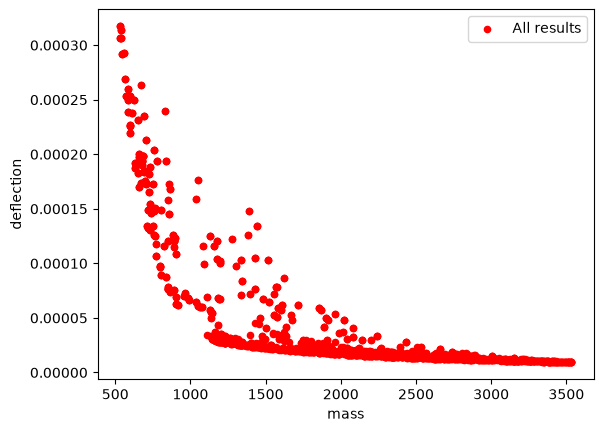

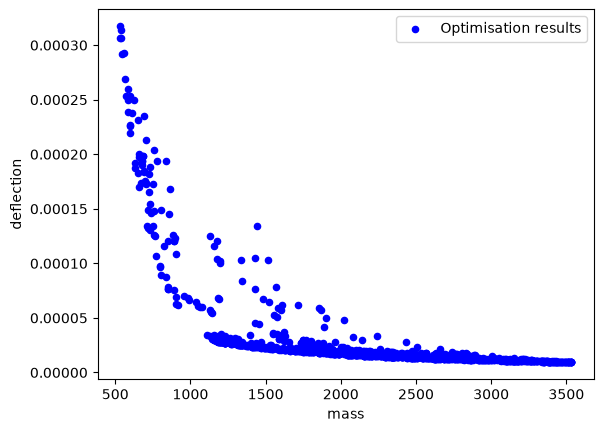

In [15]:
# All of the returned results are stored in dataframes
# Each routine stores its own results (routine.df)
# The Run Manager stores results from all of its routines in a single dataframe (runManager.df)
# You can plot each one independently, or create a combined plot.

completePlot = runner.df.plot.scatter(x='mass',y='deflection',c='r',label='All results')
optimiserPlot = optimiser.df.plot.scatter(x='mass',y='deflection',c='b',label='Optimisation results')

In [16]:
def I_beamDeflection(depth,width,**kwargs):
	I = (width * depth**3)/12 - ((width-0.1) * (depth-0.1)**3)/12
	deflection = load * length**3 / (4 * youngsModulus * I)
	return {'deflection':deflection}